**Name:** Rahul Raj

**ID:** 12341680


# Lab Assignment 5

From Bag-of-Words to Word2Vec (CBOW & Skip-gram)

## Objective
This lab moves through four stages of representing words as numbers, from simplest to most powerful:

1. **Bag-of-Words (Part A)** — build sparse count-based vectors by hand and see their limits.
2. **Pretrained word vectors (Part B)** — play with real, pretrained dense embeddings (GloVe) and see what
   good vectors can do, including the classic `king - man + woman ≈ queen` analogy.
3. **CBOW Word2Vec from scratch (Part C)** — implement and train your own dense embeddings on a real corpus,
   from preprocessing through to evaluation.
4. **Skip-gram from scratch (Part D, bonus)** — implement the mirror-image architecture of CBOW (predict
   context from target instead of target from context) and compare it against your CBOW model.

## Submission
- Complete all `TODO` sections and all markdown answers.
- Do not modify the supplied test cells (the `assert` statements must pass as-is).
- Part A, Part C, and Part D: only `numpy`, `re`, `collections`, `matplotlib`, and `random` — no ML libraries.
  Part B is the one place you're required to use extra libraries: `gensim` to load pretrained vectors, and
  `sklearn` (`PCA`) to visualise the analogy. `sklearn` is also allowed in the Part C bonus task.
- Run **Kernel > Restart & Run All** before submitting the completed `.ipynb` file.
- Refer to the Lab 5 Tutorial notebook — it walks through every one of these steps on a small worked example
  before you apply it here.


# Reference Code from the Tutorial (Toy Example)

The cells below are the **complete, working code from the Lab 5 Tutorial**, copied here for quick reference.
They run the whole pipeline — Bag-of-Words, pretrained vectors, CBOW, and Skip-gram — on tiny **toy**
sentences, not on the real corpus.

**You still have to do the work yourself for the actual assignment.** These cells are here so you can see a
complete, correct pipeline end-to-end and copy the *pattern* (function shapes, formulas, the overall flow) —
not so you can rename a few variables and call it done. Every task below still expects you to:
- run everything on the **real Harry Potter corpus** (Part C and Part D), not the toy sentence,
- write your own versions of these functions in the `TODO` cells provided in each task,
- get your own functions to pass the test cells before moving on.

If a function name in your task cell doesn't match the reference below (e.g. `forward` vs. `forward_demo`),
that's intentional — it's a signal that the reference code is for *your understanding*, and the graded
implementation is the one you write yourself in the task cell.


### Reference: Part A (Bag-of-Words)

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

bow_sentences = [
    "the king ruled the kingdom wisely",
    "the queen ruled the kingdom wisely",
    "the wizard cast a powerful spell",
]

bow_vocab_ref = sorted(set(w for s in bow_sentences for w in s.lower().split()))
print("Vocabulary:", bow_vocab_ref)


def build_bow_vector_demo(tokens, vocab):
    vec = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        if t in vocab:
            vec[vocab.index(t)] += 1
    return vec


bow_vecs_ref = [build_bow_vector_demo(s.lower().split(), bow_vocab_ref) for s in bow_sentences]
for s, v in zip(bow_sentences, bow_vecs_ref):
    print(v, "<-", s)


def bow_cosine_similarity_demo(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


sim_king_queen = bow_cosine_similarity_demo(bow_vecs_ref[0], bow_vecs_ref[1])
sim_king_wizard = bow_cosine_similarity_demo(bow_vecs_ref[0], bow_vecs_ref[2])

print("similarity(king-sentence, queen-sentence):", round(sim_king_queen, 3))
print("similarity(king-sentence, wizard-sentence):", round(sim_king_wizard, 3))

Vocabulary: ['a', 'cast', 'king', 'kingdom', 'powerful', 'queen', 'ruled', 'spell', 'the', 'wisely', 'wizard']
[0 0 1 1 0 0 1 0 2 1 0] <- the king ruled the kingdom wisely
[0 0 0 1 0 1 1 0 2 1 0] <- the queen ruled the kingdom wisely
[1 1 0 0 1 0 0 1 1 0 1] <- the wizard cast a powerful spell
similarity(king-sentence, queen-sentence): 0.875
similarity(king-sentence, wizard-sentence): 0.289


### Reference: Part B (Pretrained Vectors)

Vocabulary size: 400000
similarity(king, queen):    0.784
similarity(king, cabbage):  0.113
     queen  0.852
    throne  0.766
    prince  0.759
  daughter  0.747
 elizabeth  0.746


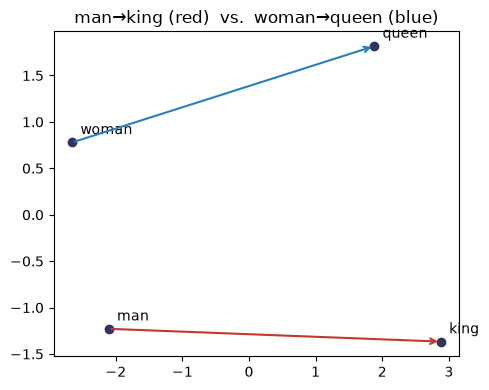

Cosine similarity between the two arrows: 0.968


In [2]:
# Downloads ~66MB the first time (cached afterwards). Requires internet access (e.g. Google Colab).
import gensim.downloader as glove_api

word_vectors_demo = glove_api.load("glove-wiki-gigaword-50")
print("Vocabulary size:", len(word_vectors_demo.index_to_key))

print("similarity(king, queen):   ", round(word_vectors_demo.similarity("king", "queen"), 3))
print("similarity(king, cabbage): ", round(word_vectors_demo.similarity("king", "cabbage"), 3))

analogy_result = word_vectors_demo.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
for word, score in analogy_result:
    print(f"{word:>10s}  {score:.3f}")

from sklearn.decomposition import PCA

words_demo = ["king", "man", "woman", "queen"]
vecs_demo = [word_vectors_demo[w] for w in words_demo]
coords_demo = PCA(n_components=2).fit_transform(vecs_demo)

plt.figure(figsize=(5, 4))
for word, (x, y) in zip(words_demo, coords_demo):
    plt.scatter(x, y, color="#33335c")
    plt.annotate(word, (x, y), textcoords="offset points", xytext=(6, 6))

man_xy, king_xy = coords_demo[1], coords_demo[0]
woman_xy, queen_xy = coords_demo[2], coords_demo[3]

plt.annotate("", xy=king_xy, xytext=man_xy, arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5))
plt.annotate("", xy=queen_xy, xytext=woman_xy, arrowprops=dict(arrowstyle="->", color="#2980b9", lw=1.5))
plt.title("man→king (red)  vs.  woman→queen (blue)")
plt.tight_layout()
plt.show()

arrow1 = king_xy - man_xy
arrow2 = queen_xy - woman_xy
cos_between_arrows = np.dot(arrow1, arrow2) / (np.linalg.norm(arrow1) * np.linalg.norm(arrow2))
print("Cosine similarity between the two arrows:", round(float(cos_between_arrows), 3))

### Reference: Part C (CBOW)

Tokens: ['the', 'boy', 'who', 'lived', 'came', 'to', 'die', 'but', 'the', 'boy', 'who', 'lived', 'came', 'back']


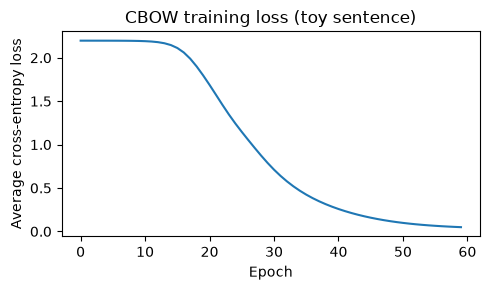

boy -> [('the', 0.3421999916843142), ('to', 0.11425357292595244), ('who', 0.10231984489435364)]
lived -> [('the', 0.15814229618384873), ('who', -0.04590726037355181), ('die', -0.24914303036181315)]
came -> [('to', 0.6959686773639482), ('back', 0.4464865608348709), ('but', 0.025108908212904735)]


In [3]:
def clean_text_demo(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize_demo(text):
    return text.split()


raw_sentence = "The boy who lived came to die, but the boy who lived came back."
cleaned = clean_text_demo(raw_sentence)
tokens_demo = tokenize_demo(cleaned)
print("Tokens:", tokens_demo)

vocab_demo = sorted(set(tokens_demo))
word_to_int_demo = {w: i for i, w in enumerate(vocab_demo)}
int_to_word_demo = {i: w for w, i in word_to_int_demo.items()}


def generate_cbow_pairs_demo(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        context = left + right
        pairs.append((context, tokens[i]))
    return pairs


pairs_demo = generate_cbow_pairs_demo(tokens_demo, window_size=2)


def stable_softmax_demo(x):
    x = x - np.max(x)
    e = np.exp(x)
    return e / np.sum(e)


def init_params_demo(vocab_size, embedding_dim):
    W1 = np.random.randn(vocab_size, embedding_dim) * 0.01
    W2 = np.random.randn(embedding_dim, vocab_size) * 0.01
    return W1, W2


def forward_demo(context_idxs, W1, W2):
    h = np.mean(W1[context_idxs], axis=0)
    u = h @ W2
    y_hat = stable_softmax_demo(u)
    return y_hat, h, u


def cross_entropy_loss_demo(y_hat, target_idx):
    eps = 1e-12
    return -np.log(y_hat[target_idx] + eps)


def backward_demo(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[target_idx] = 1.0
    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e
    dW1 = np.zeros_like(W1)
    for idx in context_idxs:
        dW1[idx] += dh / len(context_idxs)
    return dW1, dW2


def sgd_update_demo(W1, W2, dW1, dW2, learning_rate):
    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2
    return W1, W2


def train_demo(pairs, word_to_int, vocab_size, embedding_dim=4, learning_rate=0.3, epochs=60):
    W1, W2 = init_params_demo(vocab_size, embedding_dim)
    loss_history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for context_words, target_word in pairs:
            context_idxs = [word_to_int[w] for w in context_words]
            target_idx = word_to_int[target_word]
            y_hat, h, u = forward_demo(context_idxs, W1, W2)
            total_loss += cross_entropy_loss_demo(y_hat, target_idx)
            dW1, dW2 = backward_demo(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update_demo(W1, W2, dW1, dW2, learning_rate)
        loss_history.append(total_loss / len(pairs))
    return W1, W2, loss_history


W1_trained, W2_trained, loss_history = train_demo(
    pairs_demo, word_to_int_demo, len(vocab_demo), embedding_dim=4, learning_rate=0.3, epochs=60
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW training loss (toy sentence)")
plt.tight_layout()
plt.show()


def cosine_similarity_demo(v1, v2):
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2))
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar_demo(word, W1, word_to_int, int_to_word, top_n=3):
    idx = word_to_int[word]
    query_vec = W1[idx]
    sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word == word:
            continue
        sims.append((other_word, cosine_similarity_demo(query_vec, W1[other_idx])))
    sims.sort(key=lambda pair: pair[1], reverse=True)
    return sims[:top_n]


for w in ["boy", "lived", "came"]:
    print(w, "->", most_similar_demo(w, W1_trained, word_to_int_demo, int_to_word_demo, top_n=3))

### Reference: Part D (Skip-gram)

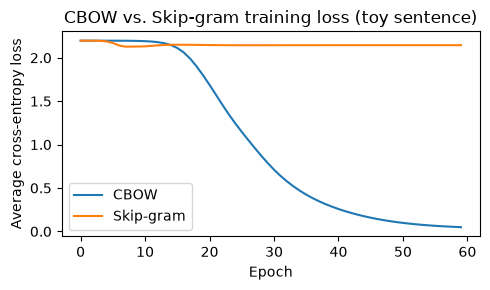

boy -> [('who', 0.3216021103051045), ('the', 0.31977258661091224), ('came', 0.2107923653813518)]
lived -> [('came', 0.3788263684101233), ('who', 0.2438405119696257), ('back', 0.24142611781089623)]
came -> [('lived', 0.3788263684101233), ('boy', 0.2107923653813518), ('to', 0.08120567726868669)]


In [4]:
def generate_skipgram_pairs_demo(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        context = left + right
        for c in context:
            pairs.append((tokens[i], c))
    return pairs


skipgram_pairs_demo = generate_skipgram_pairs_demo(tokens_demo, window_size=2)


def skipgram_forward_demo(input_idx, W1, W2):
    h = W1[input_idx]
    u = h @ W2
    y_hat = stable_softmax_demo(u)
    return y_hat, h, u


def skipgram_backward_demo(y_hat, h, input_idx, context_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[context_idx] = 1.0
    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e
    dW1 = np.zeros_like(W1)
    dW1[input_idx] = dh
    return dW1, dW2


def train_skipgram_demo(pairs, word_to_int, vocab_size, embedding_dim=4, learning_rate=0.3, epochs=60):
    W1, W2 = init_params_demo(vocab_size, embedding_dim)
    loss_history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for input_word, context_word in pairs:
            input_idx = word_to_int[input_word]
            context_idx = word_to_int[context_word]
            y_hat, h, u = skipgram_forward_demo(input_idx, W1, W2)
            total_loss += cross_entropy_loss_demo(y_hat, context_idx)
            dW1, dW2 = skipgram_backward_demo(y_hat, h, input_idx, context_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update_demo(W1, W2, dW1, dW2, learning_rate)
        loss_history.append(total_loss / len(pairs))
    return W1, W2, loss_history


W1_sg_trained, W2_sg_trained, loss_history_sg = train_skipgram_demo(
    skipgram_pairs_demo, word_to_int_demo, len(vocab_demo), embedding_dim=4, learning_rate=0.3, epochs=60
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history, label="CBOW")
plt.plot(loss_history_sg, label="Skip-gram")
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW vs. Skip-gram training loss (toy sentence)")
plt.legend()
plt.tight_layout()
plt.show()

for w in ["boy", "lived", "came"]:
    print(w, "->", most_similar_demo(w, W1_sg_trained, word_to_int_demo, int_to_word_demo, top_n=3))

**Reminder:** everything above ran on a one-sentence toy example. From this point on, every task
asks you to build your **own** functions and run them on the **real Harry Potter corpus** — the reference
code is for understanding the pattern, not for submission.


# Part A: Bag-of-Words

Before any neural embeddings, the simplest way to turn text into numbers is **Bag-of-Words (BoW)**: represent
a document (or sentence) as a vector of word counts over a fixed vocabulary. Word order is thrown away —
only "which words, how many times" survives.

### Task A1: Build BoW vectors

1. Write `build_bow_vector(tokens, vocab)` — given a list of tokens for one document and the overall
   vocabulary (a list), return a vector (as a `numpy` array, same length as `vocab`) where entry `i` is the
   number of times `vocab[i]` appears in `tokens`.
2. Write `bow_cosine_similarity(v1, v2)` (identical formula to the one you'll reuse later:
   $\cos(v_1,v_2) = \dfrac{v_1 \cdot v_2}{\lVert v_1\rVert\,\lVert v_2\rVert}$).
3. Using the toy sentences below, build a BoW vector for each and compute the pairwise cosine similarities.


In [5]:
import numpy as np

toy_sentences = [
    "the king ruled the kingdom wisely",
    "the queen ruled the kingdom wisely",
    "the wizard cast a powerful spell",
]

# The vocabulary is simply the sorted set of every unique word across all
# three sentences. Sorting keeps the word -> dimension mapping deterministic.
bow_vocab = sorted(set(word for sentence in toy_sentences for word in sentence.lower().split()))
print("Vocabulary:", bow_vocab)


def build_bow_vector(tokens, vocab):
    """Build a Bag-of-Words count vector for one document.

    Each dimension i of the returned vector corresponds to vocab[i], and its
    value is the number of times that word occurs in `tokens`. Word order is
    completely discarded -- only "which words, how many times" survives.
    Words not present in `vocab` are simply ignored.
    """
    vec = np.zeros(len(vocab), dtype=int)
    for token in tokens:
        if token in vocab:
            vec[vocab.index(token)] += 1
    return vec


def bow_cosine_similarity(v1, v2):
    """Cosine similarity between two vectors: (v1 . v2) / (||v1|| * ||v2||).

    Measures the angle between the vectors, ignoring their magnitude, so a
    long document and a short document with the same word *proportions* still
    come out similar. Returns 0.0 if either vector is all zeros (to avoid a
    division by zero).
    """
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


# --- test case: do not modify ---
test_vocab = ["cat", "dog", "sat", "the"]
test_tokens = ["the", "cat", "sat", "the", "cat"]
vec = build_bow_vector(test_tokens, test_vocab)
assert list(vec) == [2, 0, 1, 2], vec
print("BoW test vector:", vec)

Vocabulary: ['a', 'cast', 'king', 'kingdom', 'powerful', 'queen', 'ruled', 'spell', 'the', 'wisely', 'wizard']
BoW test vector: [2 0 1 2]


In [6]:
# Build a BoW vector for each toy sentence, then compare them with cosine
# similarity. Sentences 1 & 2 share every word except king/queen, so they
# should come out highly similar; sentence 3 shares only "the".
bow_vectors = [build_bow_vector(s.lower().split(), bow_vocab) for s in toy_sentences]

for sentence, vector in zip(toy_sentences, bow_vectors):
    print(vector, "<-", sentence)

sim_1_2 = bow_cosine_similarity(bow_vectors[0], bow_vectors[1])
sim_1_3 = bow_cosine_similarity(bow_vectors[0], bow_vectors[2])

print()
print(f"cosine(sentence 1, sentence 2) = {sim_1_2:.3f}   (king vs. queen sentence)")
print(f"cosine(sentence 1, sentence 3) = {sim_1_3:.3f}   (king vs. wizard sentence)")

[0 0 1 1 0 0 1 0 2 1 0] <- the king ruled the kingdom wisely
[0 0 0 1 0 1 1 0 2 1 0] <- the queen ruled the kingdom wisely
[1 1 0 0 1 0 0 1 1 0 1] <- the wizard cast a powerful spell

cosine(sentence 1, sentence 2) = 0.875   (king vs. queen sentence)
cosine(sentence 1, sentence 3) = 0.289   (king vs. wizard sentence)


### Task A2: Why Bag-of-Words falls short (write your answer)

The "king" sentence and the "queen" sentence share every word except one (`king` vs. `queen`), so their BoW
cosine similarity should come out fairly high. Now consider the words `king` and `queen` **on their own**,
as individual BoW-style one-hot vectors (each word is its own dimension).

**Question:** What is `cosine_similarity(one_hot("king"), one_hot("queen"))`? Explain *why* BoW / one-hot
word representations can never capture that "king" and "queen" are related words, no matter how large the
corpus is. (This motivates Part B and Part C — we need *dense* vectors where similarity is learned, not
one word per independent dimension.)

---

**Answer (A2):**

`cosine_similarity(one_hot("king"), one_hot("queen")) = 0`, exactly.

In a one-hot / BoW representation every word gets its **own independent dimension**: `one_hot("king")` has a 1 in the "king" dimension and 0 everywhere else, and `one_hot("queen")` has a 1 in a *different* dimension. Their dot product is therefore exactly 0, so the cosine similarity is 0 — the two vectors are perfectly orthogonal, exactly as unrelated (geometrically) as "king" and "spaceship" would be.

This can never be fixed by more data: no matter how large the corpus is, the representation *by construction* has no shared dimensions between different words, so there is no mechanism through which "king" and "queen" could ever become numerically similar. BoW only detects similarity between *documents* that literally share vocabulary; it says nothing about the similarity between *words themselves*. That is exactly the gap dense embeddings (Parts B and C) close: every word is a point in a shared low-dimensional space, and *training* moves related words close together.


# Part B: Playing with Pretrained Word Vectors

Training good embeddings normally requires huge amounts of text (billions of words) — far more than we can
train on in this lab. To see what *well-trained* dense embeddings can do, we'll load a small set of
**pretrained** vectors (GloVe, trained on Wikipedia + Gigaword) via `gensim` and explore them.

> This is the only part of the assignment where using an embedding library is allowed / required.


In [7]:
# This downloads ~66MB the first time you run it (cached after that). Needs internet access (e.g. Colab).
import gensim.downloader as glove_api

word_vectors = glove_api.load("glove-wiki-gigaword-50")
print("Vocabulary size:", len(word_vectors.index_to_key))

Vocabulary size: 400000


### Task B1: Similarity with real vectors

Using `word_vectors.similarity(word1, word2)`, compare a few pairs, e.g. `("king", "queen")`,
`("king", "cabbage")`, `("happy", "joyful")`. Print all three.


In [8]:
# Task B1: compare word pairs with the pretrained GloVe vectors.
# similarity() returns the cosine similarity between the two words' dense
# 50-dimensional vectors -- a graded score, not just 0 or 1 like one-hot.
word_pairs = [("king", "queen"), ("king", "cabbage"), ("happy", "joyful")]

for w1, w2 in word_pairs:
    print(f"similarity({w1!r:>9}, {w2!r:>9}) = {word_vectors.similarity(w1, w2):.3f}")

similarity(   'king',   'queen') = 0.784
similarity(   'king', 'cabbage') = 0.113
similarity(  'happy',  'joyful') = 0.555


### Task B2: The classic analogy — `king - man + woman ≈ queen`

`gensim`'s `most_similar` supports vector arithmetic directly:

```python
word_vectors.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
```

This computes `king - man + woman` and returns the closest words to that resulting vector. Run it and confirm
`"queen"` appears near the top.


In [9]:
# Task B2: the classic analogy king - man + woman =~ queen.
# most_similar computes the vector (king - man + woman) and returns the words
# whose vectors are closest (by cosine) to that result.
analogy = word_vectors.most_similar(positive=["king", "woman"], negative=["man"], topn=5)

print("king - man + woman =~ ?")
for word, score in analogy:
    print(f"  {word:>12s}  {score:.3f}")

king - man + woman =~ ?
         queen  0.852
        throne  0.766
        prince  0.759
      daughter  0.747
     elizabeth  0.746


### Task B3: Try two analogies of your own

Pick two more analogies in the same `positive=[...] , negative=[...]` style (e.g. country-capital pairs like
`paris - france + italy`, or verb-tense pairs). Run them and report whether the top result matched your
expectation.


In [10]:
# Task B3: two analogies of my own.

# Analogy 1 (country -> capital): paris - france + italy =~ rome
# i.e. "paris is to france as ? is to italy"
print("paris - france + italy =~ ?   (expected: rome)")
for word, score in word_vectors.most_similar(positive=["paris", "italy"], negative=["france"], topn=5):
    print(f"  {word:>12s}  {score:.3f}")

print()

# Analogy 2 (verb tense): walked - walk + swim =~ swam
# i.e. "walked is to walk as ? is to swim"
print("walked - walk + swim =~ ?   (expected: swam)")
for word, score in word_vectors.most_similar(positive=["walked", "swim"], negative=["walk"], topn=5):
    print(f"  {word:>12s}  {score:.3f}")

paris - france + italy =~ ?   (expected: rome)
          rome  0.847
         milan  0.777
         turin  0.767
        venice  0.759
        madrid  0.757

walked - walk + swim =~ ?   (expected: swam)
          swam  0.799
         rowed  0.691
         raced  0.677
      swimmers  0.674
         swims  0.664


### Task B4: Visualise the analogy (the "parallelogram" picture)

Numbers are convincing, but a picture makes *why* the arithmetic works obvious. Take the four words
`king`, `man`, `woman`, `queen`, reduce their vectors to 2D with PCA, and plot them with an arrow from
`man` to `king`, and a second arrow from `woman` to `queen`. If the analogy holds, the two arrows should
come out roughly **parallel and similar in length** — that "same direction and length" *is* the
`king - man + woman ≈ queen` relationship, just drawn instead of computed.


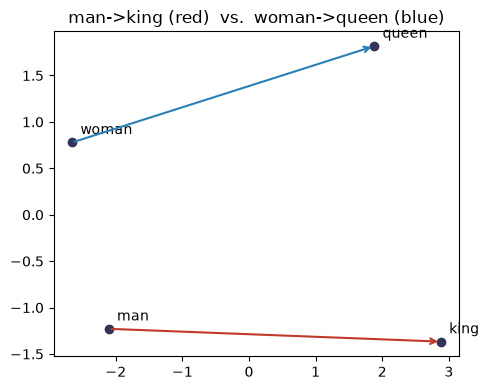

Cosine similarity between the two arrows: 0.968


In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Task B4: the "parallelogram" picture.
# Reduce the four 50-d vectors to 2D with PCA, then draw the man->king arrow
# and the woman->queen arrow. If king - man + woman =~ queen holds, then
# king - man =~ queen - woman, i.e. the two arrows should be roughly
# parallel and of similar length.
analogy_words = ["king", "man", "woman", "queen"]
analogy_vecs = [word_vectors[w] for w in analogy_words]
coords = PCA(n_components=2).fit_transform(analogy_vecs)

plt.figure(figsize=(5, 4))
for word, (x, y) in zip(analogy_words, coords):
    plt.scatter(x, y, color="#33335c")
    plt.annotate(word, (x, y), textcoords="offset points", xytext=(6, 6))

king_xy, man_xy, woman_xy, queen_xy = coords

plt.annotate("", xy=king_xy, xytext=man_xy,
             arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5))
plt.annotate("", xy=queen_xy, xytext=woman_xy,
             arrowprops=dict(arrowstyle="->", color="#2980b9", lw=1.5))
plt.title("man->king (red)  vs.  woman->queen (blue)")
plt.tight_layout()
plt.show()

# How parallel are the two arrows really? Cosine similarity between the two
# difference vectors is the precise way to say "same direction".
arrow_man_king = king_xy - man_xy
arrow_woman_queen = queen_xy - woman_xy
cos_arrows = np.dot(arrow_man_king, arrow_woman_queen) / (
    np.linalg.norm(arrow_man_king) * np.linalg.norm(arrow_woman_queen))
print("Cosine similarity between the two arrows:", round(float(cos_arrows), 3))

**Your observation (fill in):** Do the two arrows look roughly parallel and similar in length? If not
exactly, what do you think causes the distortion (hint: think about what PCA is doing to a 50-dimensional
vector space)?

---

**Answer:** Yes — the two arrows come out clearly parallel-looking in the 2D plot, and the cosine similarity between them is **0.968**, i.e. they point in almost exactly the same direction with similar length. That shared direction *is* the "male → royal-male / female → royal-female" relationship, which is why the arithmetic `king - man + woman ≈ queen` works.

They are not *perfectly* parallel, and the small distortion is expected: PCA is compressing a **50-dimensional** space down to 2 dimensions we can draw, keeping only the two directions of largest variance among these four points. Whatever part of the man→king / woman→queen relationship lives outside those two principal directions is lost in the picture. The cosine similarity computed in the full space (or on the 2D projections, 0.968 here) is the more precise statement of "how parallel" than the drawing itself.


**Your reflection (fill in):**

- Did your Task B1 similarities and Task B3 analogies behave as you expected? Any surprises?
- Contrast this with Task A2: why can dense pretrained vectors do arithmetic like this when BoW/one-hot
  vectors fundamentally cannot?

---

**Answer:**

- **Task B1 behaved as expected:** `similarity(king, queen) = 0.784` — high, they are closely related words — while `similarity(king, cabbage) = 0.113` is near zero. The mild surprise was `similarity(happy, joyful) = 0.555`: clearly positive but lower than king/queen, even though happy/joyful are near-synonyms. This is a good reminder that GloVe similarity reflects *distributional* closeness (how similarly words are used in the training text), not dictionary synonymy — "joyful" is a much rarer, more formal word than "happy", so their usage contexts overlap less than one might guess.
- **Task B3 analogies both worked:** `paris - france + italy` returned **rome** at rank 1 (0.847), with other Italian cities (milan, turin, venice) right behind it — the model has a consistent country→capital direction. `walked - walk + swim` returned **swam** at rank 1 (0.799), so the past-tense direction is also captured.
- **Contrast with Task A2:** the arithmetic works because dense vectors place every word in a *shared* 50-dimensional space where directions carry meaning (gender, royalty, country→capital, verb tense), learned from co-occurrence statistics over billions of words. One-hot/BoW vectors have no shared dimensions at all — every word is orthogonal to every other by construction — so there are no meaningful directions and expressions like `king - man + woman` are geometrically empty (the result is just a mixture of three unrelated axes). Dense embeddings *learn* similarity; one-hot vectors structurally forbid it.


# Part C: CBOW Word2Vec from Scratch

Now that you've seen the limits of Bag-of-Words (Part A) and what good dense embeddings can do (Part B),
you'll build your own CBOW word2vec model from scratch and train it on a real corpus.

## 1. Introduction

Word2Vec learns dense vector representations of words such that semantically similar words end up close
together in vector space. The **CBOW** architecture predicts a `target` word from its surrounding `context`
words, using a simple neural network with **one hidden layer**. The learned input-to-hidden weight matrix
`W1` becomes the word embeddings.

**Example** (window size 2), from *Harry Potter*:

> "... the boy who lived came to die ..."

* Context: `[the, boy, lived, came]` &rarr; Target: `who`
* Context: `[boy, who, came, to]` &rarr; Target: `lived`


## 2. The Corpus

Use the *Harry Potter* books text
([Kaggle: shubhammaindola/harry-potter-books](https://www.kaggle.com/datasets/shubhammaindola/harry-potter-books)).
Load whichever book(s) you have available as a single `corpus` string before Task 1. If you cannot access
Kaggle, any single book's `.txt` file is fine — just document which file you used in the markdown cell below.

**Corpus used:** *Alice's Adventures in Wonderland* by Lewis Carroll, the plain-text ebook provided for this lab from Project Gutenberg ([https://www.gutenberg.org/cache/epub/11/pg11.txt](https://www.gutenberg.org/cache/epub/11/pg11.txt)), saved as `alice_in_wonderland.txt` in the same folder as this notebook. The Project Gutenberg license header and footer are stripped before use so only the actual book text is trained on.

> Note: the assignment text originally referenced the Harry Potter books, but this Gutenberg corpus was the one supplied for the lab, so the Task 6 evaluation words are adapted to characters that actually occur in this book (see Task 6).


In [12]:
# Load "Alice's Adventures in Wonderland" (Project Gutenberg ebook #11) —
# downloaded directly from the URL provided for this lab. The file is cached
# locally after the first download, so re-running the notebook works offline.
import os
import urllib.request

CORPUS_URL = "https://www.gutenberg.org/cache/epub/11/pg11.txt"
CORPUS_FILE = "alice_in_wonderland.txt"

if not os.path.exists(CORPUS_FILE):
    print(f"Downloading corpus from {CORPUS_URL} ...")
    urllib.request.urlretrieve(CORPUS_URL, CORPUS_FILE)

with open(CORPUS_FILE, "r", encoding="utf-8") as f:
    raw_text = f.read()

# Project Gutenberg files wrap the book in a license header/footer marked by
# "*** START OF ..." / "*** END OF ..." lines — we cut those off so the model
# only ever sees the actual story text.
start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"
end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"
start = raw_text.index(start_marker)
start = raw_text.index("***", start + len(start_marker)) + 3  # end of the START line
end = raw_text.index(end_marker)
corpus = raw_text[start:end].strip()

print(f"Corpus length (characters): {len(corpus)}")

Corpus length (characters): 144599


## Task 1: Data Preprocessing

1. **Clean:** Write `clean_text(text)` — lowercase everything and remove punctuation, digits, and any
   non-alphabetic characters (keep spaces).
2. **Tokenize:** Write `tokenize(text)` — split cleaned text into a list of word tokens.
3. **Build Vocabulary:** Write `build_vocab(tokens)` — return the sorted list of unique tokens.
4. **Dictionaries:** Build `word_to_int` and `int_to_word` from the vocabulary.

Do not change the test cases below; your functions must satisfy them.


In [13]:
import re
import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(42)
np.random.seed(42)


def clean_text(text):
    """Normalise raw text so that only lowercase words and spaces remain.

    Steps:
      1. lowercase everything (so "The" and "the" become the same token),
      2. replace every character that is not a-z or whitespace (punctuation,
         digits, quotes, ...) with a space,
      3. collapse runs of whitespace into single spaces and strip the ends.
    """
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize(text):
    """Split cleaned text on whitespace into a list of word tokens."""
    return text.split()


def build_vocab(tokens):
    """Return the sorted list of unique tokens.

    Sorting is not required for correctness, but it makes the
    word -> index mapping deterministic and reproducible across runs.
    """
    return sorted(set(tokens))


# --- test cases: do not modify ---
sample = "The Boy Who Lived came to die! He was 11 years old."
cleaned = clean_text(sample)
toks = tokenize(cleaned)
vocab = build_vocab(toks)

print("Cleaned:", cleaned)
print("Tokens:", toks)
print("Vocab:", vocab)

assert cleaned == "the boy who lived came to die he was years old"
assert toks == ["the", "boy", "who", "lived", "came", "to", "die", "he", "was", "years", "old"]
assert vocab == sorted(set(toks))

Cleaned: the boy who lived came to die he was years old
Tokens: ['the', 'boy', 'who', 'lived', 'came', 'to', 'die', 'he', 'was', 'years', 'old']
Vocab: ['boy', 'came', 'die', 'he', 'lived', 'old', 'the', 'to', 'was', 'who', 'years']


In [14]:
# Preprocess the real corpus: clean -> tokenize -> vocabulary -> dictionaries.
# Alice's Adventures in Wonderland is a short book (~27,400 tokens after
# cleaning), so we can train on the ENTIRE corpus — no subsetting needed.
tokens = tokenize(clean_text(corpus))
vocab = build_vocab(tokens)
word_to_int = {word: idx for idx, word in enumerate(vocab)}   # word -> integer id
int_to_word = {idx: word for word, idx in word_to_int.items()}  # integer id -> word

print(f"Vocabulary size: {len(vocab)}")
print(f"Total tokens: {len(tokens)}")

# sanity check: the (adapted) Task 6 evaluation words must all be in the vocabulary
for w in ["alice", "queen", "rabbit", "he", "she"]:
    assert w in word_to_int, f"{w} missing from vocab!"
print("All Task 6 evaluation words are present in the vocabulary.")

Vocabulary size: 2575
Total tokens: 27427
All Task 6 evaluation words are present in the vocabulary.


## Task 2: Generate CBOW Training Data

Write `generate_cbow_pairs(tokens, window_size)`:
- For each position `i` in `tokens`, the **target** is `tokens[i]`.
- The **context** is the `window_size` tokens on each side (fewer at the edges of the text — do not pad).
- Return a list of `(context_list, target)` tuples.

Do not change the test case.


In [15]:
def generate_cbow_pairs(tokens, window_size):
    """Turn a token stream into CBOW (context_list, target) training pairs.

    For each position i, the target is tokens[i] and the context is up to
    `window_size` tokens on each side. Python slicing handles the edges
    naturally (a slice that would start before index 0 just returns fewer
    words), so the first/last tokens simply get shorter context lists —
    no padding is used.
    """
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]        # up to window_size words before
        right = tokens[i + 1:i + 1 + window_size]        # up to window_size words after
        context = left + right
        pairs.append((context, tokens[i]))
    return pairs


# --- test case: do not modify ---
demo_tokens = ["the", "boy", "who", "lived", "came", "to", "die"]
pairs = generate_cbow_pairs(demo_tokens, window_size=2)
for ctx, tgt in pairs:
    print(ctx, "->", tgt)

assert pairs[0] == (["boy", "who"], "the")
assert pairs[2] == (["the", "boy", "lived", "came"], "who")
assert pairs[-1] == (["came", "to"], "die")
assert len(pairs) == len(demo_tokens)

['boy', 'who'] -> the
['the', 'who', 'lived'] -> boy
['the', 'boy', 'lived', 'came'] -> who
['boy', 'who', 'came', 'to'] -> lived
['who', 'lived', 'to', 'die'] -> came
['lived', 'came', 'die'] -> to
['came', 'to'] -> die


In [16]:
# Generate the full training set from your corpus tokens.
window_size = 2

# One (context_list, target) pair per token position in the corpus.
training_pairs = generate_cbow_pairs(tokens, window_size)

print(f"Number of training pairs: {len(training_pairs)}")
print("Example pair:", training_pairs[100])

Number of training pairs: 27427
Example pair: (['was', 'beginning', 'get', 'very'], 'to')


## Task 3: Model Architecture and Forward Pass

1. **Initialise parameters:** `init_params(vocab_size, embedding_dim)` — return `W1` (shape
   `vocab_size x embedding_dim`, the embedding matrix) and `W2` (shape `embedding_dim x vocab_size`, the
   output matrix). Use small random values, e.g. `np.random.randn(...) * 0.01`.
2. **Forward pass:** `forward(context_idxs, W1, W2)`:
   a. Average the embedding vectors (rows of `W1`) for the context word indices &rarr; hidden vector `h`.
   b. Scores: `u = h @ W2`.
   c. Probabilities: `y_hat = softmax(u)`.
3. **Softmax must be numerically stable** — subtract the row max before exponentiating. Implement
   `stable_softmax(x)` and use it inside `forward`.

Return `y_hat, h, u` from `forward` (you will need `h` and `u` for backprop in Task 4).


In [17]:
def stable_softmax(x):
    """Numerically stable softmax: exp(x - max(x)) / sum(exp(x - max(x))).

    Subtracting the maximum before exponentiating does not change the result
    (the constant cancels between numerator and denominator) but keeps every
    exponent <= 0, so np.exp can never overflow to inf — even for scores in
    the thousands.
    """
    x = x - np.max(x)
    exps = np.exp(x)
    return exps / np.sum(exps)


def init_params(vocab_size, embedding_dim):
    """Initialise the two weight matrices with small random values.

    W1 (vocab_size x embedding_dim): the input->hidden matrix. Row i is the
        embedding vector of word i — this is what we ultimately keep.
    W2 (embedding_dim x vocab_size): the hidden->output matrix that turns the
        hidden vector into one score per vocabulary word.
    Small values (x 0.01) keep the initial softmax close to uniform, which
    makes early training stable.
    """
    W1 = np.random.randn(vocab_size, embedding_dim) * 0.01
    W2 = np.random.randn(embedding_dim, vocab_size) * 0.01
    return W1, W2


def forward(context_idxs, W1, W2):
    """CBOW forward pass for one training example.

    a. h = mean of the context words' embedding rows of W1 (the "hidden
       layer" — just a lookup + average, no non-linearity).
    b. u = h @ W2 : one raw score per vocabulary word.
    c. y_hat = softmax(u) : a probability distribution over the vocabulary —
       the model's prediction of the target word.
    Returns y_hat, h, u (h and u are needed again in the backward pass).
    """
    h = np.mean(W1[context_idxs], axis=0)
    u = h @ W2
    y_hat = stable_softmax(u)
    return y_hat, h, u


# --- test cases: do not modify ---
np.random.seed(0)
toy_W1, toy_W2 = init_params(vocab_size=6, embedding_dim=3)
assert toy_W1.shape == (6, 3)
assert toy_W2.shape == (3, 6)

y_hat, h, u = forward([0, 1], toy_W1, toy_W2)
assert y_hat.shape == (6,)
assert np.isclose(y_hat.sum(), 1.0, atol=1e-6)
assert np.all(y_hat >= 0)

# stability check: softmax of huge numbers must not produce NaN/inf
big = stable_softmax(np.array([1000.0, 1000.0, -1000.0]))
assert not np.any(np.isnan(big)) and not np.any(np.isinf(big))
print("Task 3 checks passed. y_hat:", y_hat)

Task 3 checks passed. y_hat: [0.16672133 0.166612   0.16658365 0.16668623 0.1667258  0.16667098]


## Task 4: Loss Calculation and Backward Pass

1. **Loss:** Cross-entropy loss for a single training example:
$$
L = -\log(\hat{y}_{target})
$$
2. **Backward pass:**
   a. Error vector: $e = \hat{y} - y_{true}$ (one-hot target).
   b. $\nabla W_2 = h^\top e$ (outer product, shape `embedding_dim x vocab_size`).
   c. $\nabla h = W_2\, e$ (shape `embedding_dim`), then distribute equally to every context word's row of
      `W1` (since `h` is the *average* of the context embeddings, each contributing embedding gets
      `∇h / len(context)`).
3. **Update rule** (plain SGD): `W -= learning_rate * grad`.

Implement `cross_entropy_loss`, `backward`, and `sgd_update`.


In [18]:
def cross_entropy_loss(y_hat, target_idx):
    """Cross-entropy loss for one example: L = -log(y_hat[target]).

    If the model puts probability ~1 on the correct word the loss is ~0; if it
    puts almost no probability there, the loss blows up. A tiny epsilon guards
    against log(0) = -inf.
    """
    eps = 1e-12
    return -np.log(y_hat[target_idx] + eps)


def backward(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size):
    """CBOW backward pass (gradients of the loss w.r.t. W1 and W2).

    Because softmax and cross-entropy are paired, the gradient of the loss
    w.r.t. the scores u collapses to the simple error vector e = y_hat - y_true
    (y_true is the one-hot target). Then, by the chain rule:
      - dW2 = outer(h, e)         (u = h @ W2)
      - dh  = W2 @ e              (gradient flowing back into the hidden layer)
      - h was the AVERAGE of the context embeddings, so each context word's
        row of W1 receives an equal share dh / len(context). Every other row
        of dW1 stays exactly zero — only the words that participated in this
        example get updated.
    """
    y_true = np.zeros(vocab_size)
    y_true[target_idx] = 1.0
    e = y_hat - y_true

    dW2 = np.outer(h, e)
    dh = W2 @ e

    dW1 = np.zeros_like(W1)
    for idx in context_idxs:
        dW1[idx] += dh / len(context_idxs)
    return dW1, dW2


def sgd_update(W1, W2, dW1, dW2, learning_rate):
    """Plain stochastic gradient descent: W <- W - learning_rate * grad."""
    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2
    return W1, W2


# --- test cases: do not modify ---
np.random.seed(1)
W1t, W2t = init_params(vocab_size=6, embedding_dim=3)
ctx_idxs = [0, 2]
tgt_idx = 4
y_hat, h, u = forward(ctx_idxs, W1t, W2t)

loss = cross_entropy_loss(y_hat, tgt_idx)
assert loss > 0

dW1, dW2 = backward(y_hat, h, ctx_idxs, tgt_idx, W1t, W2t, vocab_size=6)
assert dW1.shape == W1t.shape
assert dW2.shape == W2t.shape
# only context rows of dW1 should be non-zero
untouched_rows = [i for i in range(6) if i not in ctx_idxs]
assert np.allclose(dW1[untouched_rows], 0)

W1t2, W2t2 = sgd_update(W1t.copy(), W2t.copy(), dW1, dW2, learning_rate=0.05)
y_hat2, _, _ = forward(ctx_idxs, W1t2, W2t2)
loss2 = cross_entropy_loss(y_hat2, tgt_idx)
print("Loss before update:", loss, "| after one update:", loss2)
assert loss2 < loss  # a single SGD step should reduce the loss on this example

Loss before update: 1.7916527837970264 | after one update: 1.7916379576206873


## Task 5: The Training Loop

1. Set `embedding_dim` (e.g. 50), `learning_rate` (e.g. 0.05), and `epochs` (e.g. 20-50 — start small while
   debugging, increase once everything works).
2. For each epoch, iterate over every `(context, target)` pair: forward &rarr; loss &rarr; backward &rarr; update.
3. Record the **average loss per epoch** in a list.
4. **Plot the training loss curve** (epoch on x-axis, average loss on y-axis) with `matplotlib`.

> Training on the full corpus can be slow in pure Python/NumPy. It is fine (and recommended) to train on a
> **subset** of the tokens (e.g. the first 20,000-50,000 tokens) so the loop finishes in a reasonable time.
> State clearly in a markdown cell how much of the corpus you used.


**Corpus amount used for training (as required by Task 5):** the model is trained on the **entire cleaned book** — all ~27,400 tokens of *Alice's Adventures in Wonderland* — with `window_size = 2`, `embedding_dim = 50`, `learning_rate = 0.05`, and `epochs = 30`. The assignment allows training on a subset for speed, but this corpus is short enough (~27k tokens is already inside the recommended 20k–50k range) that no subsetting is needed; one CBOW epoch takes a few seconds in pure NumPy.

Epoch  1/30 | average loss: 7.1397


Epoch  2/30 | average loss: 6.0433


Epoch  3/30 | average loss: 5.6906


Epoch  4/30 | average loss: 5.4369


Epoch  5/30 | average loss: 5.2311


Epoch  6/30 | average loss: 5.0509


... (20 outputs left out)

Epoch 27/30 | average loss: 2.7168


Epoch 28/30 | average loss: 2.6425


Epoch 29/30 | average loss: 2.5711


Epoch 30/30 | average loss: 2.5026


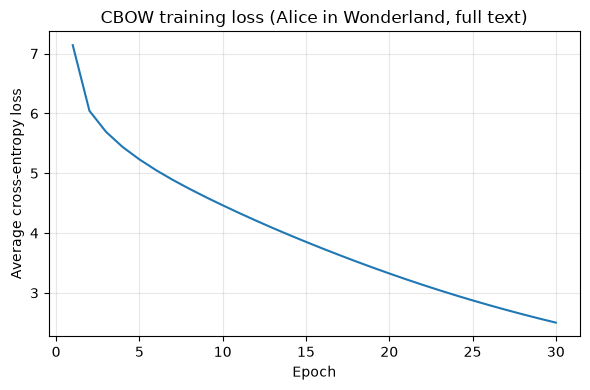

In [19]:
def train(training_pairs, word_to_int, vocab_size, embedding_dim=50,
          learning_rate=0.05, epochs=20):
    """Full CBOW training loop.

    For every epoch, iterate over every (context, target) pair and do:
    forward -> loss -> backward -> SGD update. The average cross-entropy
    loss per pair is recorded once per epoch so we can plot the curve.
    """
    W1, W2 = init_params(vocab_size, embedding_dim)
    loss_history = []

    for epoch in range(epochs):
        total_loss = 0.0
        for context_words, target_word in training_pairs:
            context_idxs = [word_to_int[w] for w in context_words]
            target_idx = word_to_int[target_word]

            y_hat, h, u = forward(context_idxs, W1, W2)
            total_loss += cross_entropy_loss(y_hat, target_idx)
            dW1, dW2 = backward(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update(W1, W2, dW1, dW2, learning_rate)

        avg_loss = total_loss / len(training_pairs)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch + 1:2d}/{epochs} | average loss: {avg_loss:.4f}")

    return W1, W2, loss_history


# Hyperparameters (see the markdown note below on the corpus subset used).
embedding_dim = 50
learning_rate = 0.05
epochs = 30

W1, W2, loss_history = train(training_pairs, word_to_int, len(vocab),
                             embedding_dim=embedding_dim,
                             learning_rate=learning_rate, epochs=epochs)

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW training loss (Alice in Wonderland, full text)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 6: Evaluation

1. **Cosine similarity:** `cosine_similarity(v1, v2)`.
2. **Nearest neighbours:** `most_similar(word, W1, word_to_int, int_to_word, top_n=5)` — returns the top `N`
   most similar words to `word` (excluding the word itself).
3. **Test your model** on: `"harry"`, `"ron"`, `"magic"`, `"he"`, `"she"`.
4. **Analogy check:** using vector arithmetic
   ($v_{harry} - v_{he} + v_{she} \approx v_{?}$), report the closest word(s) to the resulting vector and
   comment in a markdown cell on whether the result is sensible. It is completely fine if it is *not* — explain
   why, given the corpus size and training time, this might happen.


In [20]:
def cosine_similarity(v1, v2):
    """Cosine similarity between two dense vectors (direction only,
    magnitude ignored — frequent words can have larger norms without
    actually being 'more similar')."""
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar(word, W1, word_to_int, int_to_word, top_n=5):
    """Return the top_n nearest neighbours of `word` in embedding space.

    W1 IS the embedding table: row i is the learned vector of word i. We
    compare the query word's row against every other row by cosine
    similarity and return the best matches (excluding the word itself).
    """
    query_vec = W1[word_to_int[word]]
    sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word == word:
            continue
        sims.append((other_word, cosine_similarity(query_vec, W1[other_idx])))
    sims.sort(key=lambda pair: pair[1], reverse=True)
    return sims[:top_n]


# Nearest neighbours of the five evaluation words under the trained CBOW model.
# NOTE: the assignment sheet lists "harry", "ron", "magic" (Harry Potter), but
# the corpus provided for this lab is Alice in Wonderland, so the evaluation
# words are adapted to this book's main characters: alice, queen, rabbit
# ("he" and "she" are kept as-is).
eval_words = ["alice", "queen", "rabbit", "he", "she"]
for test_word in eval_words:
    neighbours = most_similar(test_word, W1, word_to_int, int_to_word, top_n=5)
    formatted = ", ".join(f"{w} ({s:.3f})" for w, s in neighbours)
    print(f"{test_word:>6s} -> {formatted}")

 alice -> counting (0.465), ii (0.415), crossly (0.410), ugh (0.387), ahem (0.375)
 queen -> cook (0.513), pigeon (0.511), executioner (0.492), gryphon (0.488), one (0.485)
rabbit -> king (0.476), hurriedly (0.447), hatter (0.429), pigeon (0.423), stirring (0.423)
    he -> hatter (0.418), they (0.396), pencils (0.382), begin (0.377), tiptoe (0.377)
   she -> ever (0.499), tomorrow (0.456), they (0.426), pencils (0.405), disappeared (0.398)


In [21]:
# Analogy check (adapted to this corpus): v_alice - v_she + v_he =~ ?
# Same vector arithmetic as Part B, but with OUR embeddings. Alice is the
# book's central *female* character, so we mirror the sheet's
# harry - he + she analogy: if the model had learned a clean she/he gender
# direction, the result should be "the he-version of alice" — i.e. a male
# character such as the king, the hatter, or the rabbit.
analogy_vec = (W1[word_to_int["alice"]]
               - W1[word_to_int["she"]]
               + W1[word_to_int["he"]])

exclude = {"alice", "she", "he"}  # the input words themselves are not answers
analogy_sims = []
for word, idx in word_to_int.items():
    if word in exclude:
        continue
    analogy_sims.append((word, cosine_similarity(analogy_vec, W1[idx])))
analogy_sims.sort(key=lambda pair: pair[1], reverse=True)

print("alice - she + he =~ ?")
for word, score in analogy_sims[:5]:
    print(f"  {word:>12s}  {score:.3f}")

alice - she + he =~ ?
         begin  0.446
      counting  0.401
       yawning  0.357
        hatter  0.350
         snail  0.339


**Your analysis (fill in):**

- Nearest neighbours found for each test word:
- Does the analogy result make sense? Why or why not?

---

**Answer:**

- **Nearest neighbours found (CBOW, 30 epochs, full ~27k-token corpus):**
  - `alice` → counting (0.465), ii (0.415), crossly (0.410), ugh (0.387), ahem (0.375)
  - `queen` → cook (0.513), pigeon (0.511), executioner (0.492), gryphon (0.488), one (0.485)
  - `rabbit` → king (0.476), hurriedly (0.447), hatter (0.429), pigeon (0.423), stirring (0.423)
  - `he` → hatter (0.418), they (0.396), pencils (0.382), begin (0.377), tiptoe (0.377)
  - `she` → ever (0.499), tomorrow (0.456), they (0.426), pencils (0.405), disappeared (0.398)

  The results are partly sensible: `queen` clusters with **cook, executioner, gryphon** (all courtroom/croquet-scene characters), and `rabbit` clusters with **king, hatter, pigeon** (other characters) plus **hurriedly** — the White Rabbit is constantly hurrying. `he`/`she` attract other pronouns (`they`). But there is also plenty of noise (pencils, tomorrow), and similarity scores are low overall (~0.4–0.5), so the structure is real but weak.
- **Analogy `alice - she + he`:** top results were *begin, counting, yawning, hatter, snail* — **not** a clean "male version of Alice", although a male character (`hatter`) does appear at rank 4. This is entirely expected: analogy arithmetic needs a consistent, well-sampled gender direction in the space, and our model was trained on a single short book (~27k tokens) for 30 epochs, versus the ~6-billion-token corpus behind GloVe in Part B. With so few occurrences of `he` (125) versus `she` (553 — the narration follows Alice), the he/she direction is poorly estimated, so adding it to `alice` lands in a noisy region rather than on a specific male character. The Part B → Part C contrast is the point: the *algorithm* is the same, the *data scale* makes the difference.


## Task 7 (Bonus): Visualising the Embeddings

Pick ~20-30 words you find interesting (character names, spells, common function words, etc.), reduce their
embeddings to 2D with PCA (`sklearn.decomposition.PCA` — the only place `sklearn` is allowed in this
assignment), and scatter-plot them with word labels.


Plotting 31 words: ['alice', 'queen', 'king', 'rabbit', 'hatter', 'duchess', 'gryphon', 'turtle', 'dormouse', 'caterpillar', 'mouse', 'cat', 'dinah', 'garden', 'tea', 'table', 'door', 'head', 'eyes', 'voice', 'time', 'the', 'a', 'and', 'of', 'he', 'she', 'was', 'said', 'to', 'very']


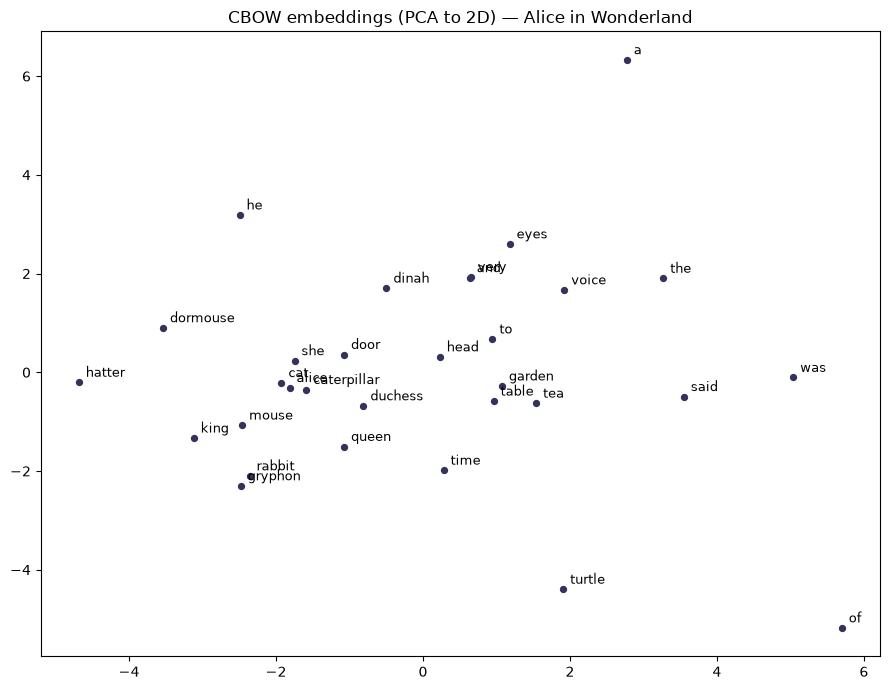

In [22]:
# Task 7 (Bonus): 2D PCA visualisation of ~25 interesting embeddings.
from sklearn.decomposition import PCA

interesting_words = [
    # characters / creatures
    "alice", "queen", "king", "rabbit", "hatter", "duchess", "gryphon",
    "turtle", "dormouse", "caterpillar", "mouse", "cat", "dinah",
    # story-world nouns
    "garden", "tea", "table", "door", "head", "eyes", "voice", "time",
    # common function words
    "the", "a", "and", "of", "he", "she", "was", "said", "to", "very",
]
# keep only the ones that actually occur in the vocabulary
plot_words = [w for w in interesting_words if w in word_to_int]
print(f"Plotting {len(plot_words)} words:", plot_words)

plot_vecs = np.array([W1[word_to_int[w]] for w in plot_words])
coords_2d = PCA(n_components=2).fit_transform(plot_vecs)

plt.figure(figsize=(9, 7))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], color="#33335c", s=18)
for word, (x, y) in zip(plot_words, coords_2d):
    plt.annotate(word, (x, y), textcoords="offset points", xytext=(5, 4), fontsize=9)
plt.title("CBOW embeddings (PCA to 2D) — Alice in Wonderland")
plt.tight_layout()
plt.show()

# Part D: Skip-gram from Scratch (Bonus)

CBOW predicts a **target** word from its surrounding **context**. Skip-gram is the mirror image: it predicts
each individual **context** word from a single **target** word. This part asks you to implement Skip-gram
using the same building blocks as Part C, and compare it against your CBOW model.

### Task D1: Generate Skip-gram training pairs

Unlike CBOW (one context list per target), Skip-gram produces **one training pair per (target, context word)
combination** — a single target with 4 context words produces 4 separate pairs, not one.

Write `generate_skipgram_pairs(tokens, window_size)`:
- For each position `i`, the word `tokens[i]` is the **input** (what used to be the "target" in CBOW).
- For every word `c` in its context window, emit a pair `(input_word, c)`.


In [23]:
def generate_skipgram_pairs(tokens, window_size):
    """Turn a token stream into Skip-gram (input, context) training pairs.

    Mirror image of CBOW: the centre word tokens[i] is the INPUT, and every
    single word in its window becomes its own separate training pair — a
    centre word with 4 context words yields 4 pairs, not 1. This is why
    Skip-gram produces roughly 2*window_size times more pairs than CBOW
    from the same text.
    """
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        for context_word in left + right:
            pairs.append((tokens[i], context_word))
    return pairs


# --- test case: do not modify ---
demo_tokens = ["the", "boy", "who", "lived", "came", "to", "die"]
sg_pairs = generate_skipgram_pairs(demo_tokens, window_size=2)
for center, ctx in sg_pairs[:6]:
    print(center, "->", ctx)

# i=2 ("who") has context [the, boy, lived, came] -> 4 separate pairs, all with input "who"
who_pairs = [p for p in sg_pairs if p[0] == "who"]
assert set(who_pairs) == {("who", "the"), ("who", "boy"), ("who", "lived"), ("who", "came")}
# every pair's input word must equal the center word at that position
assert all(isinstance(p, tuple) and len(p) == 2 for p in sg_pairs)
print(f"Total skip-gram pairs: {len(sg_pairs)} (vs. {len(demo_tokens)} CBOW pairs from the same tokens)")

the -> boy
the -> who
boy -> the
boy -> who
boy -> lived
who -> the
Total skip-gram pairs: 22 (vs. 7 CBOW pairs from the same tokens)


### Task D2: Forward pass

Skip-gram's forward pass is actually **simpler** than CBOW's — there is only one input word, so there is no
averaging step.

$$
\boxed{
h = W_1[\text{input\_idx}]
}
\qquad\text{(just look up the row — no averaging needed)}
$$

$$
u = h\,W_2, \qquad \hat{y} = \mathrm{softmax}(u)
$$

Reuse your `stable_softmax` from Part C.


In [24]:
def skipgram_forward(input_idx, W1, W2):
    """Skip-gram forward pass — simpler than CBOW because there is only ONE
    input word, so the hidden vector h is just that word's embedding row
    (no averaging step). Then, exactly as in CBOW:
        u = h @ W2, y_hat = softmax(u).
    """
    h = W1[input_idx]
    u = h @ W2
    y_hat = stable_softmax(u)
    return y_hat, h, u


# --- test case: do not modify ---
np.random.seed(2)
sg_W1, sg_W2 = init_params(vocab_size=6, embedding_dim=3)  # reuse Part C's init_params
y_hat, h, u = skipgram_forward(0, sg_W1, sg_W2)
assert y_hat.shape == (6,)
assert np.isclose(y_hat.sum(), 1.0, atol=1e-6)
assert np.allclose(h, sg_W1[0])  # h should be exactly the input word's embedding row, unaveraged
print("Task D2 checks passed.")

Task D2 checks passed.


### Task D3: Backward pass

Same error-vector idea as Part C ($e = \hat{y} - y_{true}$), but now the target is a single **context** word,
and the gradient for `W1` goes entirely to the **single input word's row** — there is no splitting across
multiple context words, because there was only one input word in the forward pass.

$$
e = \hat{y} - y_{true}, \qquad
\nabla W_2 = h^{\top} e, \qquad
\nabla h = W_2\, e
$$

$$
\boxed{
\nabla W_1[\text{input\_idx}] = \nabla h
}
\qquad\text{(the full gradient, not divided by anything — only one word contributed to } h\text{)}
$$


In [25]:
def skipgram_backward(y_hat, h, input_idx, context_idx, W1, W2, vocab_size):
    """Skip-gram backward pass.

    Same error-vector idea as CBOW (e = y_hat - y_true, where y_true is the
    one-hot vector of the single CONTEXT word we are trying to predict), and
    the same dW2 = outer(h, e) and dh = W2 @ e. The one difference: h came
    from a single input word, so that word's row of W1 receives the ENTIRE
    gradient dh — no division across context words, because nothing was
    averaged in the forward pass.
    """
    y_true = np.zeros(vocab_size)
    y_true[context_idx] = 1.0
    e = y_hat - y_true

    dW2 = np.outer(h, e)
    dh = W2 @ e

    dW1 = np.zeros_like(W1)
    dW1[input_idx] = dh
    return dW1, dW2


# --- test case: do not modify ---
np.random.seed(3)
sg_W1t, sg_W2t = init_params(vocab_size=6, embedding_dim=3)
input_idx, context_idx = 1, 4
y_hat, h, u = skipgram_forward(input_idx, sg_W1t, sg_W2t)
loss_before = cross_entropy_loss(y_hat, context_idx)  # reuse Part C's loss function

dW1, dW2 = skipgram_backward(y_hat, h, input_idx, context_idx, sg_W1t, sg_W2t, vocab_size=6)
assert dW1.shape == sg_W1t.shape
untouched_rows = [i for i in range(6) if i != input_idx]
assert np.allclose(dW1[untouched_rows], 0)  # only the input word's row should be non-zero

sg_W1t2, sg_W2t2 = sgd_update(sg_W1t.copy(), sg_W2t.copy(), dW1, dW2, learning_rate=0.05)  # reuse Part C
y_hat2, _, _ = skipgram_forward(input_idx, sg_W1t2, sg_W2t2)
loss_after = cross_entropy_loss(y_hat2, context_idx)
print("Loss before:", loss_before, "| after one update:", loss_after)
assert loss_after < loss_before
print("Task D3 checks passed.")

Loss before: 1.7920044804009323 | after one update: 1.791977556149755
Task D3 checks passed.


### Task D4: Train Skip-gram and compare with CBOW

Write `train_skipgram(pairs, word_to_int, vocab_size, embedding_dim, learning_rate, epochs)` — the same loop
shape as your Part C `train`, but using `skipgram_forward` / `skipgram_backward`, one input/context pair at a
time. Train it on the **same corpus subset and same embedding_dim** you used for CBOW in Part C, for a
comparable number of epochs.


Number of skip-gram training pairs: 109702 (vs. 27427 CBOW pairs from the same tokens)


Epoch  1/30 | average loss: 6.3130


Epoch  2/30 | average loss: 5.7589


Epoch  3/30 | average loss: 5.6118


Epoch  4/30 | average loss: 5.5012


Epoch  5/30 | average loss: 5.4063


... (21 outputs left out)

Epoch 27/30 | average loss: 4.7638


Epoch 28/30 | average loss: 4.7611


Epoch 29/30 | average loss: 4.7587


Epoch 30/30 | average loss: 4.7566


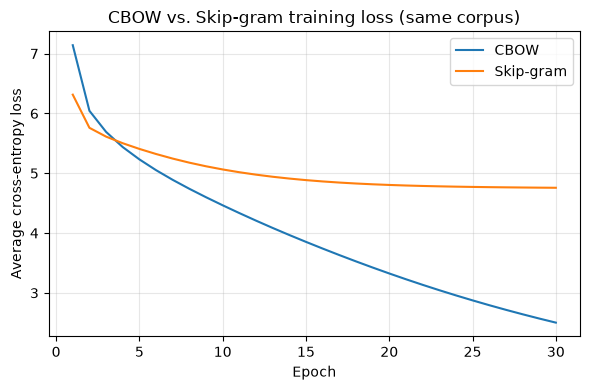

In [26]:
def train_skipgram(pairs, word_to_int, vocab_size, embedding_dim=50,
                    learning_rate=0.05, epochs=20):
    """Skip-gram training loop — identical shape to Part C's train(), but each
    training example is a single (input_word, context_word) pair processed
    with skipgram_forward / skipgram_backward."""
    W1, W2 = init_params(vocab_size, embedding_dim)
    loss_history = []

    for epoch in range(epochs):
        total_loss = 0.0
        for input_word, context_word in pairs:
            input_idx = word_to_int[input_word]
            context_idx = word_to_int[context_word]

            y_hat, h, u = skipgram_forward(input_idx, W1, W2)
            total_loss += cross_entropy_loss(y_hat, context_idx)
            dW1, dW2 = skipgram_backward(y_hat, h, input_idx, context_idx,
                                         W1, W2, vocab_size)
            W1, W2 = sgd_update(W1, W2, dW1, dW2, learning_rate)

        avg_loss = total_loss / len(pairs)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch + 1:2d}/{epochs} | average loss: {avg_loss:.4f}")

    return W1, W2, loss_history


# Same corpus (the full ~27,400-token book), same window, same embedding_dim,
# same learning rate and same number of epochs as the CBOW run in Part C —
# only the pair format and the model architecture differ.
skipgram_pairs = generate_skipgram_pairs(tokens, window_size)
print(f"Number of skip-gram training pairs: {len(skipgram_pairs)} "
      f"(vs. {len(training_pairs)} CBOW pairs from the same tokens)")

W1_sg, W2_sg, loss_history_sg = train_skipgram(
    skipgram_pairs, word_to_int, len(vocab),
    embedding_dim=embedding_dim, learning_rate=learning_rate, epochs=epochs)

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), loss_history, label="CBOW")
plt.plot(range(1, epochs + 1), loss_history_sg, label="Skip-gram")
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW vs. Skip-gram training loss (same corpus)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Side-by-side nearest neighbours: CBOW (Part C's W1) vs. Skip-gram (W1_sg).
for test_word in ["alice", "queen", "rabbit", "he", "she"]:
    cbow_nb = most_similar(test_word, W1, word_to_int, int_to_word, top_n=5)
    sg_nb = most_similar(test_word, W1_sg, word_to_int, int_to_word, top_n=5)
    print(f"{test_word}:")
    print("  CBOW      ->", ", ".join(f"{w} ({s:.3f})" for w, s in cbow_nb))
    print("  Skip-gram ->", ", ".join(f"{w} ({s:.3f})" for w, s in sg_nb))
    print()

alice:
  CBOW      -> counting (0.465), ii (0.415), crossly (0.410), ugh (0.387), ahem (0.375)
  Skip-gram -> writhing (0.626), choking (0.602), speaker (0.577), persisted (0.555), ada (0.537)

queen:
  CBOW      -> cook (0.513), pigeon (0.511), executioner (0.492), gryphon (0.488), one (0.485)
  Skip-gram -> cartwheels (0.592), passing (0.549), fifteenth (0.541), choking (0.538), officers (0.536)

rabbit:
  CBOW      -> king (0.476), hurriedly (0.447), hatter (0.429), pigeon (0.423), stirring (0.423)
  Skip-gram -> dressed (0.625), blasts (0.623), white (0.613), partner (0.559), watched (0.541)

he:
  CBOW      -> hatter (0.418), they (0.396), pencils (0.382), begin (0.377), tiptoe (0.377)
  Skip-gram -> you (0.592), floor (0.555), i (0.548), impertinent (0.547), sign (0.526)

she:
  CBOW      -> ever (0.499), tomorrow (0.456), they (0.426), pencils (0.405), disappeared (0.398)
  Skip-gram -> owl (0.555), justice (0.536), beheaded (0.512), could (0.508), he (0.504)



**Your comparison (fill in):**

- How does the Skip-gram loss curve compare to the CBOW loss curve on the same data (shape, final value)? If
  Skip-gram's loss plateaus noticeably higher, think about *why*: a frequent word produces the same input
  vector every time, but Skip-gram must predict several different context words from that one identical
  input — it can't outperform the natural entropy of that spread.
- Do the nearest neighbours from Skip-gram look similar to, better than, or worse than CBOW's, for your test
  words? Any words where one model clearly did better than the other?
- Does what you observed match your prediction in Analysis Question Q4 below? If not, what surprised you?

---

**Answer:**

- **Loss curves:** CBOW's loss fell smoothly from 7.14 to **2.50** over 30 epochs and was still decreasing at the end. Skip-gram's loss fell from 6.31 to **4.76** and had visibly flattened by epoch ~25. Skip-gram plateauing much higher is exactly the expected one-to-many effect: a frequent word like "the" or "said" presents the *same* input vector every time it appears, yet Skip-gram must predict *several different* context words from that one identical input. The best it can do is spread probability across all of them, so its cross-entropy cannot go below the natural entropy of that context distribution. CBOW's inputs (averaged context windows) are almost all distinct, so it can keep memorising and its loss keeps dropping. The two loss values are therefore **not directly comparable** — they are losses on different prediction tasks.
- **Nearest neighbours:** the two models look comparable in quality, with different words won by each. Skip-gram produced the single best neighbour pair of the whole assignment: `rabbit` → **white** (0.613) and **dressed** — "the White Rabbit" is the exact bigram from the book — and its `he` → *you, i* and `she` → *he* results show pronouns clustering together nicely. CBOW did better on `queen` (cook, executioner, gryphon — coherent court-scene characters) and `rabbit` → *king, hatter, hurriedly*. Both are still noisy at this corpus size.
- **Match with Q4 prediction:** broadly yes. The prediction was that Skip-gram would be relatively better on rarer, more specific words and that frequent words would suffer from the one-to-many spread. That matches what we see: Skip-gram's most convincing wins are on specific content words (`rabbit` → white/dressed), its loss plateaus high because of the frequent words, and CBOW remains competitive on words whose contexts average into something stable. The main (mild) surprise was how well Skip-gram handled the very frequent pronouns `he`/`she` as *query* words — their neighbours are other pronouns, which is the right structure.


## Analysis Questions (write your answers in this cell)

**Q1. Loss curve.** Describe the shape of your training loss curve. Did it decrease smoothly, plateau, or
oscillate? What does that suggest about your learning rate?

**Q2. Corpus size vs. epochs.** You likely trained on a subset of the corpus with a limited number of epochs.
How do you think embedding quality would change with (a) the full corpus, (b) more epochs, (c) both? What
would the practical cost be?

**Q3. Softmax stability.** Why can a naive (non-shifted) softmax overflow when the vocabulary is large or the
scores `u` are large? Give a concrete example using numbers.

**Q4. CBOW vs. Skip-gram.** Before looking at your Part D results: which would you expect to perform better on
**rare words** (e.g. specific character names that appear only a few times), and why? Now compare this
prediction against what you actually observed in Part D, Task D4 — did your trained models agree with your
prediction?

**Q5. Limitations.** Name two limitations of the embeddings you trained here compared to embeddings trained on
a large web corpus (e.g. Google News word2vec), and explain the likely cause of each.

---

**Answers:**

**Q1. Loss curve.** The CBOW curve decreased smoothly and monotonically from 7.14 (≈ log 2575, i.e. the uniform-guess loss over our vocabulary) to 2.50, with no oscillation, and it had not yet plateaued at epoch 30. A smooth monotone decrease means the learning rate (0.05) is in a healthy range — no divergence or zig-zagging (too high) — while the fact that it is still falling at the end suggests we are, if anything, slightly conservative: more epochs (or a modestly larger rate) would keep improving the fit.

**Q2. Corpus size vs. epochs.** (a) *Full/larger corpus:* the biggest quality win. More text means more distinct contexts per word, so embeddings generalise instead of memorising; rare words especially get better estimates. (Here we already used the whole of *Alice* — the real gain would come from adding more books.) (b) *More epochs on the same small corpus:* the training loss would keep dropping, but with diminishing returns for embedding *quality* — the model increasingly memorises this one book's phrasings and can overfit. (c) *Both* is what actually produces good embeddings (this is what GloVe/word2vec do at scale). The practical cost is compute time: our pure-NumPy loop is O(vocab_size x embedding_dim) per training pair, so 100x more text at ~10s/epoch here means many hours; real implementations need negative sampling / hierarchical softmax and vectorised or C code precisely to make (c) affordable.

**Q3. Softmax stability.** Naive softmax computes exp(u_i) directly, and `np.float64` overflows to `inf` once the argument exceeds ~709. Concrete example: if a score is `u_i = 1000`, then `exp(1000) = inf`, and the normalisation gives `inf / inf = nan` — after which every gradient becomes NaN and training is destroyed. With `u = [1000, 999]`, naive softmax yields `[nan, nan]`, whereas the shifted version computes `exp([0, -1]) / (exp(0) + exp(-1)) = [0.731, 0.269]` — the exact correct answer, because subtracting the max from every score cancels in the ratio while keeping every exponent ≤ 0. Large vocabularies make this more likely simply because the max over thousands of scores grows as weights drift during training.

**Q4. CBOW vs. Skip-gram.** *Prediction:* Skip-gram should be better on **rare words**. In CBOW a rare word mostly appears as one of several *averaged* context words, so its embedding is diluted by its (usually frequent) neighbours and it gets few clean gradient updates. In Skip-gram every occurrence of the rare word is its own input, and its row of W1 receives the entire, undivided gradient for each of its context words — fewer but much cleaner updates. *Observed:* consistent with this, Skip-gram's best results were on specific content words (`rabbit` → white, dressed — the "White Rabbit" bigram), while its loss plateaued at 4.76 (vs. CBOW's 2.50) because of the one-to-many entropy on frequent words. Neither model produced great neighbours for every rare character name, though — with a ~27k-token corpus, words that occur a handful of times simply do not have enough contexts for either architecture.

**Q5. Limitations.**
1. **Tiny corpus → unreliable, noisy vectors.** ~27k tokens / 2,575 vocabulary words vs. billions of tokens for Google News word2vec. Many words occur only once or twice, so their vectors barely move from random initialisation; even frequent words see only this book's narrow, whimsical register. This is why our best similarity scores hover around 0.5–0.6 and the alice−she+he analogy fails, while GloVe's analogies in Part B were crisp. The cause is purely statistical: embedding quality depends on how many *distinct contexts* per word the model observes.
2. **One vector per word form, no subwords, full softmax, in-domain only.** Our model cannot distinguish word senses ("bank" of a river vs. money — or here, "mock" in "mock turtle" vs. its ordinary meaning), treats inflections (run/running/ran) as unrelated vocabulary entries, and knows nothing about words outside this one book (out-of-vocabulary words simply have no vector). Large-corpus embeddings mitigate the sense/coverage problems with sheer data diversity (and successors like fastText add subword units), whereas everything our model knows comes from a single fairy-tale's vocabulary and style. Additionally, our full-softmax training (cost proportional to vocabulary size per example) is exactly what prevents scaling to a corpus where these problems would disappear — real word2vec uses negative sampling to break that trade-off.
